# Optimisation Lead — v2: Block-Level Accessibility
### From town centroids to every HDB block: does it change the recommendation?

v1 described every flat in a town with one set of accessibility numbers (the town's centroid).
This notebook re-does the prescriptive layer with **every HDB block individually geocoded** and asks,
with evidence at each step:

1. **Coverage** — what was geocoded, and how reliably
2. **Block accessibility** — true per-block distances to 12 amenity layers
3. **Does block-level matter?** — within-town variation; hedonic price effect beyond town; out-of-time test
4. **Granularity decision** — town vs town × MRT band vs pure block
5. **v2 profiles** — with block distributions and a block drill-down layer
6. **Recommender v2** — reformulated objective (hedonic value gap + household preference tilt)
7. **Monte Carlo** — buy now vs wait, on a simulator calibrated at the new granularity
8. **Sensitivity** — monotonicity, preference sweep, "price of insisting on Near-MRT"
9. **Backtest** — 6 cutoffs × 3 households, v2 vs v1 vs naive, across two iterations
10. **Iteration log, limitations, and handoff notes**


## Iteration log (what changed, and why)
| # | Finding | Change |
|---|---|---|
| 0 | Geocoding "failed" at ~5% | Root cause was HTTP 429 rate-limiting silently swallowed as "not found". Fixed with explicit 429 handling, backoff, pacing, per-area checkpoints → 13,356/13,357 blocks, 1,699/1,703 childcare, 439/444 supermarkets, 335/337 schools |
| 1 | Master Plan 2019 rail layer includes **unopened** stations (Jurong Region Line, Cross Island Line) | Current access uses LTA's operating station-exit layer; planned stations kept as a separate *future-access* feature |
| 2 | Market already prices MRT proximity (~1%/100m) | Objective rebuilt: surplus = shrunk hedonic value gap + household-vs-market preference tilt (raw attribute value would double-count what the price already reflects) |
| 3 | Budget-monotonicity check **failed** | Cardinality was `min(k, feasible towns)`, so more budget forced extra negative-value picks. Fixed: k held fixed; "fewer than k towns feasible" reported as its own outcome |
| 4 | Backtest iter 1: v2 within-budget 95.3% vs v1 100% | Stub ±15% band was sized for town-level volatility; finer cells move more. Replaced with an empirical, granularity-aware 90% band → 98.8% |
| 5 | v1 availability stub divided by an arbitrary "20 units" | Replaced with the buyer-relevant quantity: arrival rate of matching sales (sales/12 per month) |
| 6 | LTA's exit layer is missing **5 operating stations** (Punggol Coast, Hume, and the 3 CCL6 stations Keppel / Cantonment / Prince Edward Rd); 2,141 sales were credited with stations not yet open | Exits patched from OneMap; distance is now **date-aware** for all 40 stations opened since 2017 (DTL3, Canberra, TEL1–4, the patched 5): each sale is measured against the network open *in its own month* |
| 7 | "Primary school" layer contained 11 secondary/JC schools (filter matched "MIXED LEVEL"); linear school distance had a counter-intuitive sign | P1-only filter (182 schools); school access re-specified as **MOE-style tiers** (within 1km / 1–2km / beyond 2km). SAP/GEP tiers carry a clean +2.5–3% premium; "any primary" is saturated (97% within 1km) |
| 8 | Distances were straight-line | Built the full OSM pedestrian network (566k nodes) and computed walking distance for every block; tested whether it explains price better (it does not — see §3.4) |
| 9 | "~5% of picks see no matching sale" was unexplained | Calibration check: the availability stub predicted it (every >30%-risk pick came up empty; none of the 66 picks rated <1% did) — §7.1 |


In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mticker

import block_accessibility as ba
import block_analysis as ban
import housing_profiles_v2 as hp2
import recommender_v2 as rv2
import recommender as rv1
import monte_carlo as mc
import sensitivity_v2 as sv2
import empirical_bands as eb

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 180)
DATA = rv2.DATA
kfmt = mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}k")

## 1. Geocoding coverage

In [2]:
PROC = os.path.join(ba.ROOT, "data", "processed")
cov = []
for label, f in [("HDB blocks", "hdb_blocks_geocoded.csv"), ("Primary/secondary schools", "schools_geocoded_v2.csv"),
                 ("Childcare & kindergartens", "childcare_postal_geocoded_v2.csv"), ("Supermarkets", "supermarkets_geocoded_v2.csv")]:
    d = pd.read_csv(os.path.join(PROC, f))
    cov.append({"layer": label, "attempted": len(d), "geocoded_ok": int((d["status"] == "OK").sum())})
cov = pd.DataFrame(cov); cov["success_pct"] = cov["geocoded_ok"] / cov["attempted"] * 100
cov

,layer,attempted,geocoded_ok,success_pct
0,HDB blocks,13357,13356,99.992513
1,Primary/secondary schools,335,335,100.000000
2,Childcare & kindergartens,1703,1699,99.765120
3,Supermarkets,462,439,95.021645


## 2. Block-level accessibility
Straight-line (haversine) distance from each block to the nearest feature, plus counts within walking radii.
**Rail uses LTA's operating station-exit layer** (closer to real walking access than a station centroid),
**patched with 5 operating stations missing from it** (Punggol Coast, Hume, Keppel, Cantonment, Prince Edward Road —
exits from OneMap, opening dates verified). **Distances are date-aware**: the 40 stations that opened during the
2017+ resale window (DTL3 Oct 2017, Canberra 2019, TEL stages 2020–2024, the 5 patched) only count for sales after
they opened. Master Plan stations not yet operating are a separate *future-access* feature.

In [3]:
blocks = pd.read_csv(os.path.join(DATA, "block_accessibility.csv"))
res = blocks[blocks["residential"] == "Y"]
_, meta = ba.load_amenity_layers()
print(f"Residential blocks: {len(res):,} | operating MRT stations: {meta['n_operating_mrt_stations']} | "
      f"LRT: {meta['n_operating_lrt_stations']} | planned/not-in-operating-layer: {len(meta['planned_station_names'])}")
dcols = [c for c in res.columns if c.startswith("dist_")]
(res[dcols].describe(percentiles=[.1, .5, .9]).T[["mean", "10%", "50%", "90%", "max"]] * 1000).round(0).rename(
    columns=lambda c: c + " (m)")

Residential blocks: 10,795 | operating MRT stations: 147 | LRT: 41 | planned/not-in-operating-layer: 41


,mean (m),10% (m),50% (m),90% (m),max (m)
dist_mrt_exit_km,712.0,234.0,618.0,1327.0,3545.0
dist_mrt_exit_base_km,807.0,270.0,718.0,1486.0,3545.0
dist_lrt_exit_km,4784.0,298.0,5197.0,8249.0,13723.0
dist_planned_rail_km,2435.0,486.0,1645.0,6374.0,9880.0
dist_bus_stop_km,115.0,50.0,107.0,188.0,437.0
dist_primary_school_km,423.0,163.0,374.0,732.0,3309.0
dist_primary_elite_km,3560.0,588.0,2885.0,7842.0,10758.0
dist_hawker_km,729.0,201.0,644.0,1379.0,2511.0
dist_supermarket_km,364.0,127.0,320.0,637.0,3326.0
dist_chas_clinic_km,214.0,69.0,185.0,381.0,2734.0


In [4]:
pg = json.load(open(os.path.join(ba.GEO, "MRT_exits_patch_onemap.geojson")))
patched = pd.DataFrame([f["properties"] for f in pg["features"]])
patched["opened"] = patched["STATION_NA"].map(ba.PATCH_OPENING_DATES)
display(patched.groupby(["STATION_NA", "opened"]).size().rename("exits_patched").reset_index())
tx0 = ban.load_transactions_with_access()
moved = tx0[tx0["dist_mrt_exit_km_at_sale"] > tx0["dist_mrt_exit_km"] + 1e-6]
print(f"Sales measured against the network open at sale date: {len(moved):,} sales get a LONGER distance than "
      f"today's network (station not yet open when they sold); {(tx0['mrt_band_at_sale'] != tx0['mrt_band']).sum():,} change band.")

,STATION_NA,opened,exits_patched
0,CANTONMENT MRT STATION,2026-07-12,3
1,HUME MRT STATION,2025-02-28,2
2,KEPPEL MRT STATION,2026-07-12,3
3,PRINCE EDWARD ROAD MRT STATION,2026-07-12,2
4,PUNGGOL COAST MRT STATION,2024-12-10,2


Sales measured against the network open at sale date: 7,957 sales get a LONGER distance than today's network (station not yet open when they sold); 5,027 change band.


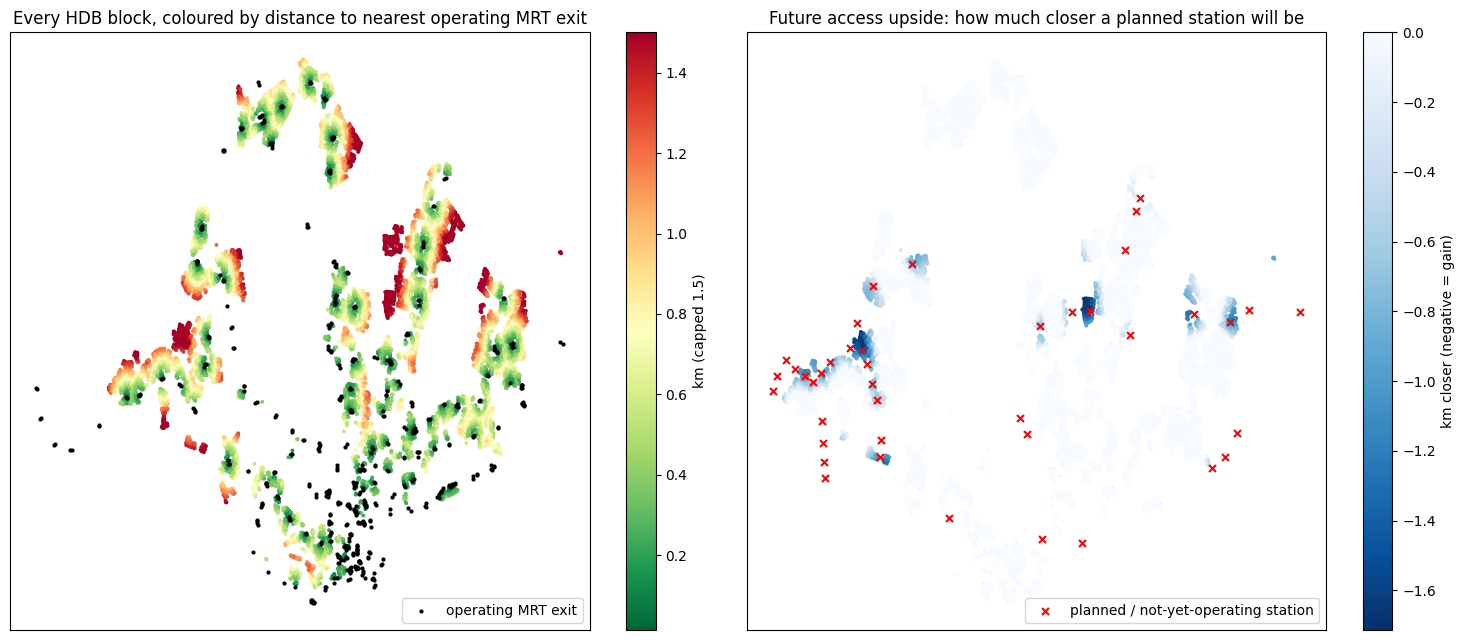

In [5]:
layers, _ = ba.load_amenity_layers()
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
sc = axes[0].scatter(res["lon"], res["lat"], c=res["dist_mrt_exit_km"].clip(upper=1.5), cmap="RdYlGn_r", s=3)
axes[0].scatter(layers["mrt_exit"]["lon"], layers["mrt_exit"]["lat"], s=4, c="black", label="operating MRT exit")
axes[0].set_title("Every HDB block, coloured by distance to nearest operating MRT exit")
plt.colorbar(sc, ax=axes[0], label="km (capped 1.5)"); axes[0].legend(loc="lower right")
sc2 = axes[1].scatter(res["lon"], res["lat"], c=(res["dist_planned_rail_km"] - res["dist_mrt_exit_km"]).clip(-2, 0),
                      cmap="Blues_r", s=3)
axes[1].scatter(layers["planned_rail"]["lon"], layers["planned_rail"]["lat"], marker="x", c="red", s=25,
                label="planned / not-yet-operating station")
axes[1].set_title("Future access upside: how much closer a planned station will be")
plt.colorbar(sc2, ax=axes[1], label="km closer (negative = gain)"); axes[1].legend(loc="lower right")
for a in axes: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 3. Does block-level accessibility matter?
### 3.1 How much variation do town centroids throw away?
Share of each feature's variance (across blocks) that lies **within** towns — invisible to a town-level feature.

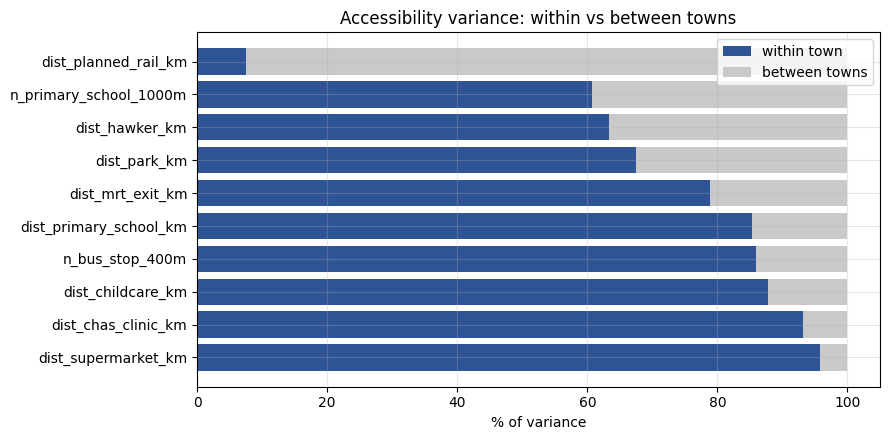

,feature,within_town_share,between_town_share
4,dist_supermarket_km,0.957,0.043
5,dist_chas_clinic_km,0.932,0.068
8,dist_childcare_km,0.877,0.123
7,n_bus_stop_400m,0.859,0.141
1,dist_primary_school_km,0.853,0.147
0,dist_mrt_exit_km,0.788,0.212
6,dist_park_km,0.674,0.326
3,dist_hawker_km,0.633,0.367
2,n_primary_school_1000m,0.606,0.394
9,dist_planned_rail_km,0.075,0.925


In [6]:
tx = ban.load_transactions_with_access()
tx["price_psm"] = tx["resale_price"] / tx["floor_area_sqm"]
vd = ban.variance_decomposition(tx, ban.ACCESS_FEATURES)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(vd["feature"], vd["within_town_share"] * 100, color="#2f5496", label="within town")
ax.barh(vd["feature"], vd["between_town_share"] * 100, left=vd["within_town_share"] * 100, color="#c9c9c9", label="between towns")
ax.set_xlabel("% of variance"); ax.set_title("Accessibility variance: within vs between towns"); ax.legend()
plt.tight_layout(); plt.show()
vd.round(3)

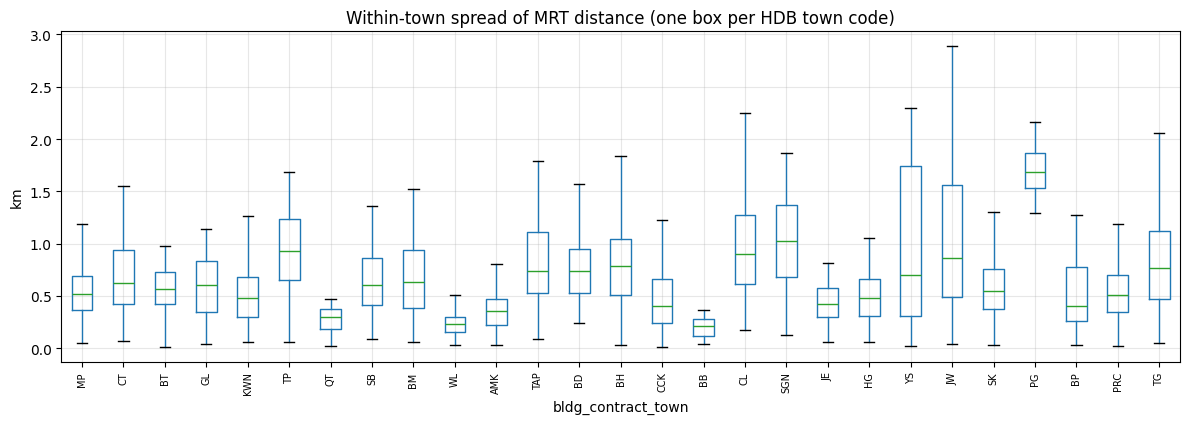

In [7]:
order = res.groupby("bldg_contract_town")["dist_mrt_exit_km"].median().sort_values().index
fig, ax = plt.subplots(figsize=(12, 4.5))
res.boxplot(column="dist_mrt_exit_km", by="bldg_contract_town", ax=ax, positions=range(len(order)), showfliers=False)
ax.set_xticklabels(order, rotation=90, fontsize=7); plt.suptitle("")
ax.set_title("Within-town spread of MRT distance (one box per HDB town code)"); ax.set_ylabel("km")
plt.tight_layout(); plt.show()

### 3.2 Hedonic test: does it explain price beyond the town?
Both models include month, flat type, flat model, storey, floor area, lease (quadratic) and **town fixed effects**.
Model B adds block accessibility. Standard errors clustered by block. 80k-transaction sample.

In [8]:
d, m_a, m_b = ban.hedonic_models(tx, sample_n=80_000)
print(f"Adj R²  town FE only: {m_a.rsquared_adj:.4f}  |  + block accessibility: {m_b.rsquared_adj:.4f}")
print(f"Residual SE (log pts): {np.sqrt(m_a.mse_resid):.4f} -> {np.sqrt(m_b.mse_resid):.4f} "
      f"({(1-np.sqrt(m_b.mse_resid)/np.sqrt(m_a.mse_resid))*100:.1f}% lower)")
coef = ban.coefficient_table(m_b); coef.round(3)

Adj R²  town FE only: 0.9184  |  + block accessibility: 0.9347
Residual SE (log pts): 0.0998 -> 0.0892 (10.6% lower)


,feature,coef_log,pct_effect_per_unit,ci_low_pct,ci_high_pct,p_value,pct_per_100m_closer
0,dist_mrt_exit_km_at_sale,-0.113,-10.669,-11.095,-10.242,0.000,1.135
1,dist_primary_school_km,0.023,2.305,1.259,3.361,0.000,-0.228
2,n_primary_school_1000m,-0.006,-0.611,-0.757,-0.465,0.000,NaN
3,dist_hawker_km,-0.018,-1.765,-2.159,-1.370,0.000,0.178
4,dist_supermarket_km,-0.025,-2.498,-3.457,-1.530,0.000,0.253
5,dist_chas_clinic_km,-0.029,-2.859,-4.896,-0.779,0.007,0.291
6,dist_park_km,-0.009,-0.903,-1.401,-0.403,0.000,0.091
7,n_bus_stop_400m,0.001,0.070,0.016,0.124,0.011,NaN
8,dist_childcare_km,0.032,3.250,-0.285,6.912,0.072,-0.319
9,dist_planned_rail_km,-0.004,-0.369,-0.638,-0.099,0.007,0.037


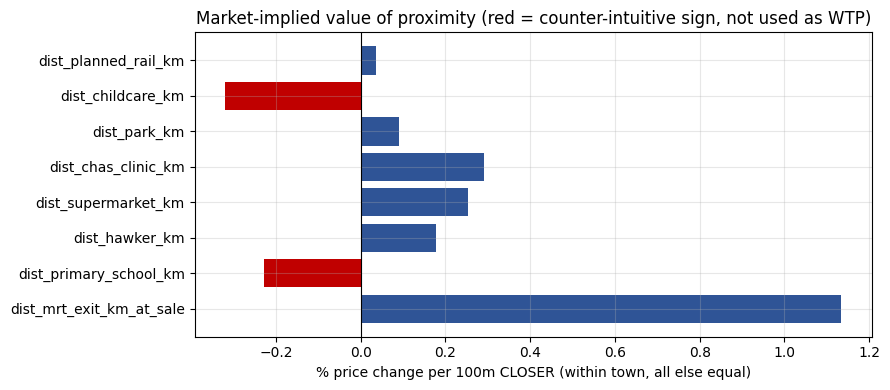

In [9]:
c = coef[coef["feature"].str.startswith("dist_")].copy()
fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#2f5496" if v > 0 else "#c00000" for v in c["pct_per_100m_closer"]]
ax.barh(c["feature"], c["pct_per_100m_closer"], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("% price change per 100m CLOSER (within town, all else equal)")
ax.set_title("Market-implied value of proximity (red = counter-intuitive sign, not used as WTP)")
plt.tight_layout(); plt.show()

**Reading the coefficients.** MRT dominates: ≈ **+1.1% price per 100m closer** to an MRT exit (measured on the network open at each sale date),
tight confidence interval. Supermarket, hawker, clinic and park proximity are smaller but correctly signed.
**Linear primary-school and childcare distance come out counter-intuitive** (closer = slightly cheaper).
A *linear* distance is the wrong specification: almost every HDB block has some primary school within 1km,
and what buyers pay for is **P1 ballot priority at a popular school**, which MOE allocates in straight-line
distance *tiers*. §3.3 re-specifies school access that way.

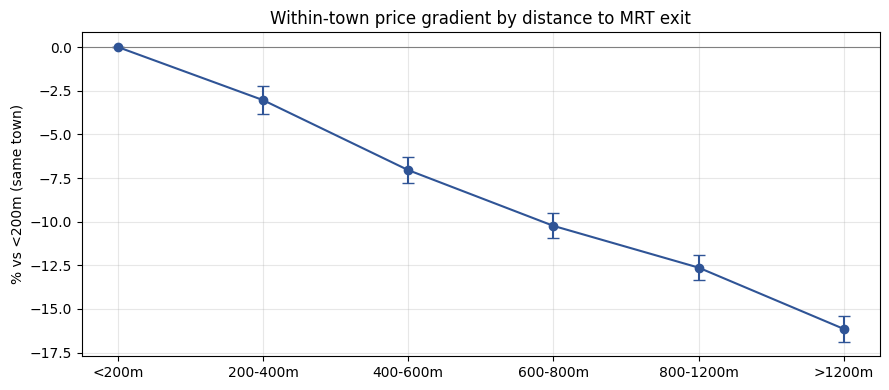

,band,pct_vs_<200m,ci_low,ci_high,n_txn
0,<200m,0.00,0.00,0.00,14532
1,200-400m,-3.04,-3.83,-2.24,40477
2,400-600m,-7.05,-7.79,-6.30,50353
3,600-800m,-10.24,-10.96,-9.51,45330
4,800-1200m,-12.63,-13.33,-11.92,51518
5,>1200m,-16.14,-16.87,-15.41,34075


In [10]:
grad = ban.mrt_distance_gradient(tx)
fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(grad["band"], grad["pct_vs_<200m"], yerr=[grad["pct_vs_<200m"] - grad["ci_low"], grad["ci_high"] - grad["pct_vs_<200m"]],
            fmt="o-", color="#2f5496", capsize=4)
ax.axhline(0, color="gray", lw=0.8); ax.set_ylabel("% vs <200m (same town)")
ax.set_title("Within-town price gradient by distance to MRT exit")
plt.tight_layout(); plt.show()
grad.round(2)

In [11]:
oot = ban.out_of_time_test(tx)
print("Train on 2017-2024, test on 2025-2026 (unseen period):")
oot.round(3)

Train on 2017-2024, test on 2025-2026 (unseen period):


,MAPE_pct,RMSE_sgd,n_test
town_fixed_effects_only,16.119,128439.505,39386.0
plus_block_accessibility,15.801,126252.859,39386.0


### 3.3 School and childcare access as tiers (1km / 2km / beyond)
MOE's Primary 1 registration gives priority by **straight-line** home–school distance: *within 1km*, then
*1–2km*, then *beyond 2km*. Tiers therefore stay straight-line by design (walking distance would mis-assign them).
- **Any primary school**: tier of the nearest P1 school (182 schools; secondary/JC excluded).
- **SAP / GEP primary** (20 schools): the oversubscribed schools where the 1km priority actually decides a ballot —
  our proxy for "popular school" until a popularity / balloting dataset is added.
- **Childcare**: the 1km/2km cut is saturated (every block has one within 1km), so it is also cut finer:
  within 200m / 200–500m / beyond 500m.

In [12]:
tiers = pd.concat({c: res[c].value_counts(normalize=True).mul(100).round(1)
                   for c in ["primary_tier", "elite_primary_tier", "childcare_tier", "childcare_band"]}, axis=1)
print("Share of residential blocks in each tier (%):"); display(tiers)
m_st, st, st_mrt = ban.school_tier_test(tx)
print("Hedonic with tiers (town FE, clustered by block); % price effect vs the reference level:")
st.round(3)

Share of residential blocks in each tier (%):


,primary_tier,elite_primary_tier,childcare_tier,childcare_band
Within 1km,97.0,20.2,100.0,NaN
1-2km,2.9,18.7,NaN,NaN
Beyond 2km,0.0,61.2,0.0,NaN
Within 200m,NaN,NaN,NaN,82.4
200-500m,NaN,NaN,NaN,16.8
Beyond 500m,NaN,NaN,NaN,0.8


Hedonic with tiers (town FE, clustered by block); % price effect vs the reference level:


,term,pct_effect,ci_low,ci_high,p_value,n_txn_in_level
0,elite_primary_tier = 1-2km,2.912,2.128,3.702,0.000,22945
1,elite_primary_tier = Within 1km,2.644,1.783,3.511,0.000,22349
2,primary_tier = Beyond 2km,49.599,30.581,71.386,0.000,44
3,primary_tier = Within 1km,-4.100,-5.489,-2.690,0.000,116292
4,childcare_band = 200-500m,-3.225,-6.174,-0.184,0.038,18191
5,childcare_band = Within 200m,-2.938,-5.889,0.107,0.058,100659


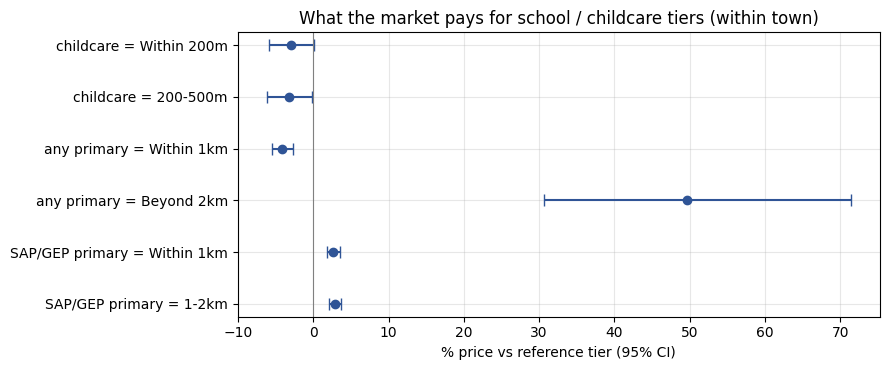

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.8))
y = st["term"].str.replace("elite_primary_tier", "SAP/GEP primary").str.replace("primary_tier", "any primary").str.replace(
    "childcare_band", "childcare")
ax.errorbar(st["pct_effect"], y, xerr=[st["pct_effect"] - st["ci_low"], st["ci_high"] - st["pct_effect"]], fmt="o",
            color="#2f5496", capsize=4)
ax.axvline(0, color="gray", lw=0.8); ax.set_xlabel("% price vs reference tier (95% CI)")
ax.set_title("What the market pays for school / childcare tiers (within town)")
plt.tight_layout(); plt.show()

**Reading it.**
- **SAP/GEP within 1km or 1–2km ≈ +2.5–3%** vs beyond 2km, clean and significant: this is the P1-priority premium,
  and it is now used as the market rate for the "needs primary school" goal (`elite_primary_1_2km` in
  `market_wtp_coefficients.json`).
- **"Any primary"** carries no usable signal — 97% of blocks are within 1km, so the comparison level is tiny
  and noisy. It is kept as a descriptive share only.
- **Childcare**: blocks within 200m or 200–500m of a centre trade ~3% *below* the few blocks beyond 500m
  (borderline significance). With childcare this ubiquitous, the "beyond 500m" group is mostly newer, less dense
  estates — the sign reflects estate type, not a dislike of childcare. It is reported, not optimised on.

In the recommender a household picks `school_goal` = `elite_1km` / `elite_2km` / `any_1km`; the shortfall is
priced at the market tier premium × the household's school multiplier.

### 3.4 Straight-line vs walking distance — can we track the real walk?
We downloaded the full OpenStreetMap pedestrian network for Singapore (footpaths, linkways, overhead bridges,
walkable roads; **566k nodes, unsimplified**) and ran one multi-source Dijkstra per amenity layer, giving the
network walking distance from every HDB block to its nearest MRT exit, hawker centre, supermarket, etc.

Two versions: **raw OSM**, and **OSM + 25m connectors** — every pair of path nodes within 25m that OSM does not
join gets an edge, standing in for unmapped zebra crossings, void-deck walk-throughs and covered linkways.

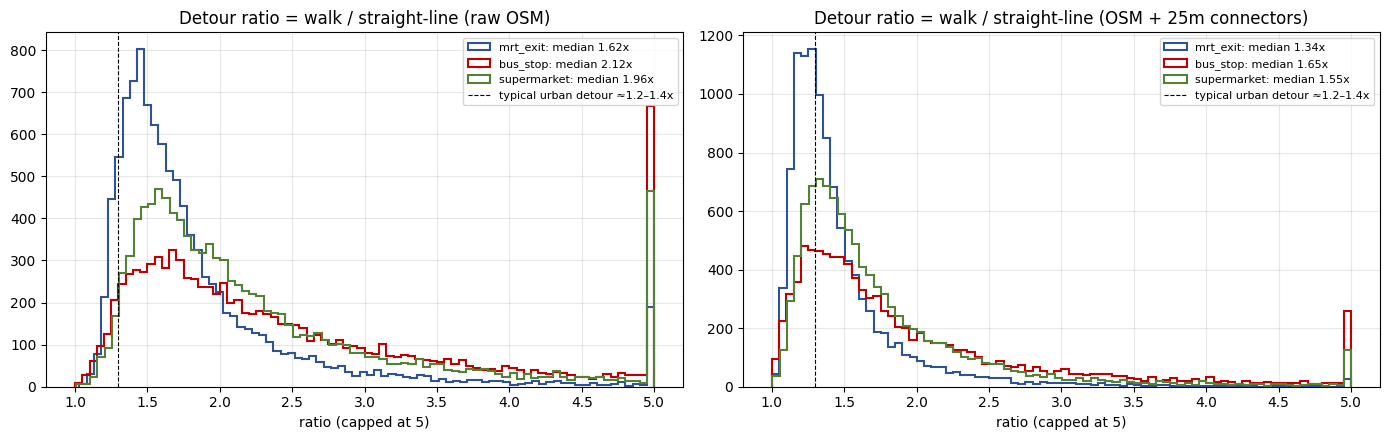

In [14]:
walk_raw = pd.read_csv(os.path.join(DATA, "block_walk_distances.csv"))
walk_con = pd.read_csv(os.path.join(DATA, "block_walk_distances_connect25m.csv"))
r_ = res[["query", "dist_mrt_exit_km", "dist_bus_stop_km", "dist_supermarket_km"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (lbl, w) in zip(axes, [("raw OSM", walk_raw), ("OSM + 25m connectors", walk_con)]):
    m = r_.merge(w, on="query")
    for k, col in [("mrt_exit", "#2f5496"), ("bus_stop", "#c00000"), ("supermarket", "#548235")]:
        s, wk = m[f"dist_{k}_km"], m[f"walk_{k}_km"]
        ok = (s > 0.05) & wk.notna()
        ax.hist((wk[ok] / s[ok]).clip(upper=5), bins=80, histtype="step", lw=1.5, color=col,
                label=f"{k}: median {(wk[ok]/s[ok]).median():.2f}x")
    ax.axvline(1.3, color="black", ls="--", lw=0.8, label="typical urban detour ≈1.2–1.4x")
    ax.set_title(f"Detour ratio = walk / straight-line ({lbl})"); ax.set_xlabel("ratio (capped at 5)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [15]:
ex_q = "153 JALAN TECK WHYE" if (res["query"] == "153 JALAN TECK WHYE").any() else res["query"].iloc[0]
print("Example (traced route):", ex_q)
display(r_[r_["query"] == ex_q].merge(walk_raw, on="query")[["dist_bus_stop_km", "walk_bus_stop_km"]].join(
    r_[r_["query"] == ex_q].merge(walk_con, on="query")[["walk_bus_stop_km"]].rename(columns={"walk_bus_stop_km": "walk_bus_stop_km_connected"})))
cmp_ = pd.read_csv(os.path.join(DATA, "walk_variant_comparison.csv"))
cmp_.pivot(index="metric", columns="variant", values="value").round(4)

Example (traced route): 1 BEACH RD


,dist_bus_stop_km,walk_bus_stop_km,walk_bus_stop_km_connected
0,0.051201,0.229728,0.067505


variant,OSM + 25m connectors,OSM raw
metric,,
AIC_both,-56176.2918,-50015.8920
AIC_straight-line MRT,-56056.3393,-49976.4087
AIC_walking MRT,-55802.3719,-48296.9941
adjR2_both,0.9222,0.9222
adjR2_straight-line MRT,0.9219,0.9221
adjR2_walking MRT,0.9213,0.9173
median_detour_CHAS clinic,1.6726,2.0870
median_detour_MRT exit,1.3433,1.6215
median_detour_SAP/GEP primary,1.3512,1.7576


**Reading it (AIC is comparable only within a variant — the usable sample differs).**
- **Raw OSM is not trustworthy for HDB estates**: median detour 1.6× to MRT and 2.1× to a bus stop (typical
  urban networks are 1.2–1.4×); 64% of blocks have a >1.5× detour. Route traces show why — e.g. a bus stop 107m
  away routed ~1.3km round a block because OSM is missing the crossing / void-deck path. Using it would push
  ~4,900 blocks into a farther MRT band.
- **Bridging ≤25m gaps** brings the MRT detour to a plausible **1.34×** and halves the >1.5× share (29%).
- **Price test**: even the corrected walking distance does **not** explain resale price better than straight-line
  (adj R² 0.9213 vs 0.9219); with both in the model, straight-line carries most of the effect.

**Decision.** Straight-line stays the model and profile input (it is also what MOE's P1 tiers use). The
gap-corrected walking distances are merged as `walk_*_km` columns and shown in the block drill-down, so a household
sees "~870m walk" as well as "620m away". To validate further, a sample of blocks can be checked against
OneMap's routing API (needs a free account token).

## 4. Granularity decision
A profile must be (a) **thick enough** to price and forecast (≥3 sales in 12 months) and
(b) **homogeneous enough** that its accessibility number describes the flats in it.

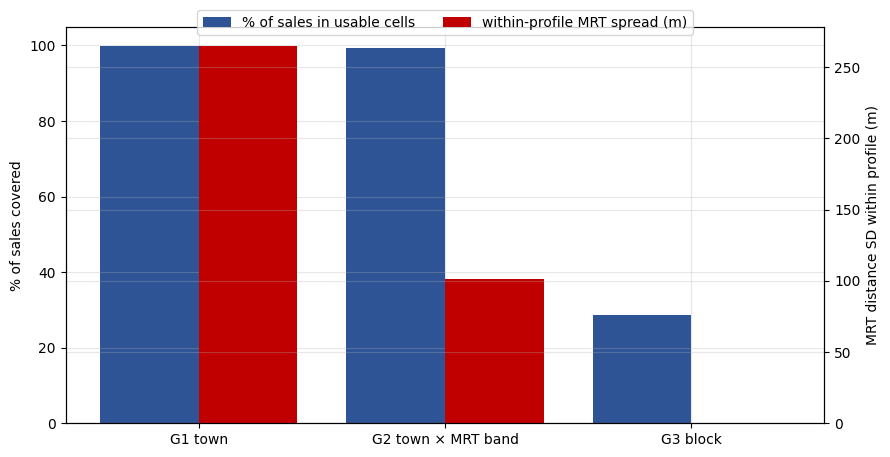

,granularity,cells_total,cells_usable(>=3 txn/12mo),pct_txn_in_usable_cells,median_within_cell_psm_CV,median_within_cell_MRT_sd_m,towns_covered
0,G1: town x flat_type x storey,344,322,99.88,11.32,264.97,26
1,G2: G1 x MRT band (Near/Mid/Far),828,712,99.27,9.93,101.43,26
2,G3: block x flat_type x storey,15304,1848,28.53,3.14,0.00,26


In [16]:
gran = ban.granularity_comparison(tx)
fig, ax1 = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(gran))
ax1.bar(x - 0.2, gran["pct_txn_in_usable_cells"], 0.4, color="#2f5496", label="% of sales in usable cells")
ax2 = ax1.twinx()
ax2.bar(x + 0.2, gran["median_within_cell_MRT_sd_m"], 0.4, color="#c00000", label="within-profile MRT spread (m)")
ax1.set_xticks(x); ax1.set_xticklabels(["G1 town", "G2 town × MRT band", "G3 block"])
ax1.set_ylabel("% of sales covered"); ax2.set_ylabel("MRT distance SD within profile (m)")
fig.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02)); plt.tight_layout(); plt.show()
gran.round(2)

**Decision: G2 = town × flat type × storey band × MRT band** (Near ≤400m / Mid 400–800m / Far >800m).
- **vs G1 (town)**: same coverage (99.3% vs 99.9%), but within-profile MRT spread falls **266m → 102m** and price
  dispersion falls (CV 11.3% → 9.9%). The 400m/800m cut-offs sit on the observed price gradient and match
  ~5- and ~10-minute walks.
- **vs G3 (pure block)**: G3 is perfectly homogeneous but only **28.5%** of sales sit in cells with enough data —
  unforecastable for most of the market.
- **Blocks are not discarded**: every G2 profile carries its block distribution (p10/p50/p90) and the list of
  blocks behind it, so the dashboard can drill down to actual addresses.

## 5. v2 profiles

In [17]:
prof = pd.read_csv(os.path.join(DATA, "housing_profiles_v2_full.csv"))
print(f"{len(prof)} profiles | {prof['town'].nunique()} towns | bands: {prof['mrt_band'].value_counts().to_dict()}")
prof[["profile_id", "median_price", "txn_count_12m", "n_blocks", "dist_mrt_exit_km_p10", "dist_mrt_exit_km_p50",
      "dist_mrt_exit_km_p90", "essentials_score", "share_primary_1km", "annual_turnover_pct", "hedonic_value",
      "hedonic_gap"]].sample(10, random_state=3).round(3)

712 profiles | 26 towns | bands: {'Mid': 248, 'Near': 236, 'Far': 228}


,profile_id,median_price,txn_count_12m,n_blocks,dist_mrt_exit_km_p10,dist_mrt_exit_km_p50,dist_mrt_exit_km_p90,essentials_score,share_primary_1km,annual_turnover_pct,hedonic_value,hedonic_gap
246,CLEMENTI::3ROOM::Mid::Near,455000.0,31,15,0.160,0.244,0.385,4.806,1.000,1.615,470250.483,15250.483
690,YISHUN::3ROOM::Low::Near,440000.0,43,31,0.148,0.231,0.370,4.186,1.000,2.011,400577.831,-39422.169
81,BISHAN::EXECUTIVE::Low::Mid,1195000.0,10,6,0.430,0.579,0.748,3.900,1.000,3.257,1246816.129,51816.129
322,JURONG EAST::3ROOM::Low::Far,370000.0,27,17,0.899,1.334,1.568,3.296,0.259,1.731,369057.100,-942.900
177,BUKIT PANJANG::5ROOM::Low::Far,621000.0,32,30,0.879,1.183,1.586,3.750,1.000,2.216,626387.750,5387.750
180,BUKIT PANJANG::5ROOM::Mid::Mid,716944.0,28,24,0.441,0.646,0.704,4.071,1.000,1.640,715570.378,-1373.622
194,BUKIT TIMAH::5ROOM::Low::Near,1050000.0,5,4,0.129,0.357,0.394,4.800,1.000,1.866,1026881.222,-23118.778
506,SEMBAWANG::3ROOM::Low::Far,494000.0,10,6,0.807,0.878,0.996,2.700,0.600,4.902,460341.562,-33658.438
485,QUEENSTOWN::3ROOM::Mid::Near,430000.0,43,24,0.171,0.305,0.376,4.070,0.674,1.148,460876.031,30876.031
101,BUKIT BATOK::4ROOM::High::Near,765000.0,3,2,0.177,0.177,0.306,3.333,1.000,1.402,688891.865,-76108.135


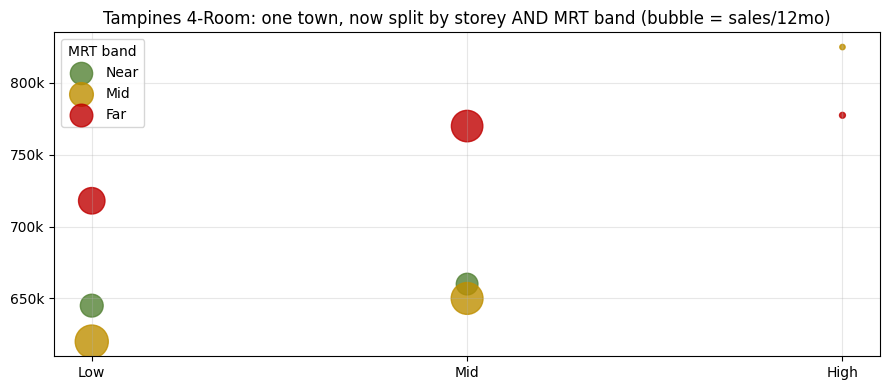

In [18]:
t = prof[(prof["town"] == "TAMPINES") & (prof["flat_type"] == "4 ROOM")].sort_values(["storey_band", "mrt_band"])
fig, ax = plt.subplots(figsize=(9, 4))
for band, col in [("Near", "#548235"), ("Mid", "#bf8f00"), ("Far", "#c00000")]:
    s = t[t["mrt_band"] == band]
    ax.scatter(s["storey_band"], s["median_price"], s=s["txn_count_12m"] * 3, color=col, label=band, alpha=0.8)
ax.yaxis.set_major_formatter(kfmt); ax.legend(title="MRT band")
ax.set_title("Tampines 4-Room: one town, now split by storey AND MRT band (bubble = sales/12mo)")
plt.tight_layout(); plt.show()

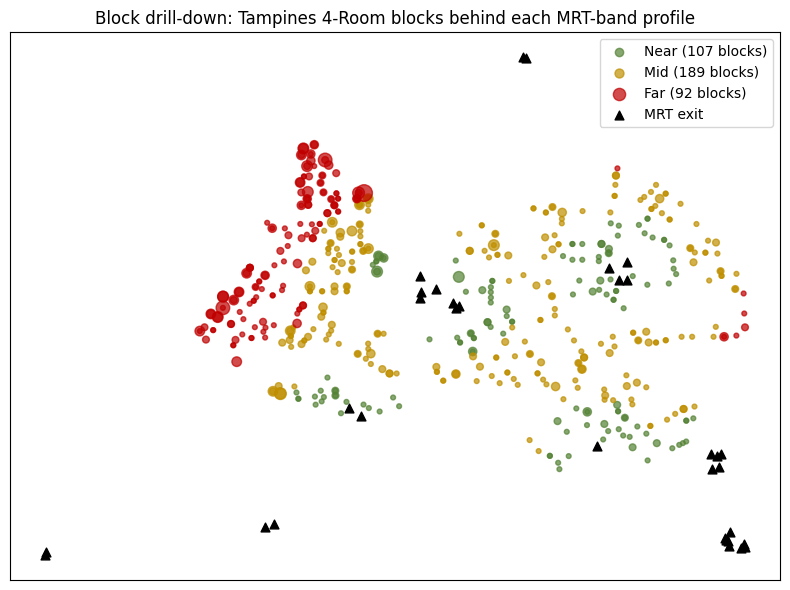

In [19]:
drill = pd.read_csv(os.path.join(DATA, "profile_block_drilldown.csv"))
tb = drill[(drill["town"] == "TAMPINES") & (drill["flat_type"] == "4 ROOM")]
fig, ax = plt.subplots(figsize=(8, 6))
for band, col in [("Near", "#548235"), ("Mid", "#bf8f00"), ("Far", "#c00000")]:
    s = tb[tb["mrt_band"] == band]
    ax.scatter(s["lon"], s["lat"], s=s["sales_12m"] * 12, color=col, label=f"{band} ({s['query'].nunique()} blocks)", alpha=0.7)
mx = layers["mrt_exit"]; mx = mx[(mx["lon"].between(tb["lon"].min()-.01, tb["lon"].max()+.01)) & (mx["lat"].between(tb["lat"].min()-.01, tb["lat"].max()+.01))]
ax.scatter(mx["lon"], mx["lat"], marker="^", c="black", s=40, label="MRT exit")
ax.legend(); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Block drill-down: Tampines 4-Room blocks behind each MRT-band profile")
plt.tight_layout(); plt.show()

## 6. Recommender v2
**Objective (SGD):** maximise Σ x_p · (surplus_p − goal deviation_p)

- **surplus = shrunk hedonic value gap + preference tilt.** The gap is how far a profile trades below what its
  attributes are worth, shrunk by n/(n+10) so thin cells can't dominate (a "cheap" profile may also have
  unmeasured negatives — noise, orientation, condition). The tilt values attributes at
  *(household multiplier − 1) × market rate*: a household valuing MRT access exactly like the market gets
  **zero** surplus from it, because the price already reflects it.
- **goal deviations:** MRT distance beyond target (priced at the market MRT rate × multiplier), walkable-essentials
  shortfall, school-tier shortfall (if needed: share of the profile's blocks *not* within 1km/2km of a SAP/GEP
  primary, priced at the market tier premium), storey below target, and expected wait beyond target —
  **waiting priced at the real median HDB rent** for that town and flat type.
- **hard constraints (proposal):** budget ≥ upper price band (empirical, granularity-aware 90%), lease ≥ minimum,
  **≤ 1 profile per town**, exactly k.

In [20]:
bands12 = eb.empirical_growth_bands(tx[tx["flat_type"] != "MULTI-GENERATION"], horizon=12)
bands6 = eb.empirical_growth_bands(tx[tx["flat_type"] != "MULTI-GENERATION"], horizon=6)
archetypes = {
    "Young couple, transit-reliant": dict(budget=600_000, min_lease_yrs=60, flat_types=["3 ROOM", "4 ROOM"],
                                           target_mrt_km=0.4, multipliers={"mrt": 1.5}),
    "Family, needs primary school": dict(budget=800_000, min_lease_yrs=65, flat_types=["4 ROOM", "5 ROOM"],
                                          target_mrt_km=0.6, needs_primary_school=True, target_storey="Mid"),
    "Budget-first, car owner": dict(budget=480_000, min_lease_yrs=55, target_mrt_km=1.0,
                                     multipliers={"mrt": 0.5}, target_essentials=3.0),
}
results = {}
for name, a in archetypes.items():
    r = rv2.solve(rv2.HouseholdQuery2(k=5, name=name, **a), upper_factors=bands12)
    results[name] = r
    print(f"\n=== {name} — {r['status']}, {r['n_candidates']} candidates, {r['n_feasible_towns']} towns ===")
    display(r["shortlist"][["rank", "profile_id", "price_today", "price_upper", "dist_mrt_exit_km_p50",
                            "essentials_score", "share_elite_primary_2km", "expected_wait_months",
                            "p_no_matching_sale_3m", "surplus",
                            "goal_deviation_total", "net_objective_value"]].round(2))


=== Young couple, transit-reliant — Optimal, 27 candidates, 8 towns ===


,rank,profile_id,price_today,price_upper,dist_mrt_exit_km_p50,essentials_score,share_elite_primary_2km,expected_wait_months,p_no_matching_sale_3m,surplus,goal_deviation_total,net_objective_value
13,1,HOUGANG::3ROOM::Mid::Near,496000.0,595200.00,0.36,4.20,1.0,2.40,0.29,5409.26,0.00,5409.26
3,2,BUKIT BATOK::3ROOM::Mid::Near,421444.0,505732.80,0.25,3.75,0.0,0.75,0.02,6374.38,2000.00,4374.38
21,3,WOODLANDS::3ROOM::Mid::Mid,508000.0,597432.00,0.52,3.82,0.0,0.55,0.00,6923.71,10822.39,-3898.68
26,4,YISHUN::4ROOM::Low::Mid,500888.0,597059.81,0.61,4.05,0.0,0.12,0.00,17977.90,31110.24,-13132.34
9,5,CHOA CHU KANG::3ROOM::Low::Mid,430000.0,505700.32,0.59,4.25,0.0,1.50,0.14,-4112.02,27546.05,-31658.07



=== Family, needs primary school — Optimal, 82 candidates, 14 towns ===


,rank,profile_id,price_today,price_upper,dist_mrt_exit_km_p50,essentials_score,share_elite_primary_2km,expected_wait_months,p_no_matching_sale_3m,surplus,goal_deviation_total,net_objective_value
2,1,BUKIT PANJANG::4ROOM::High::Mid,650000.0,774801.70,0.64,4.85,0.00,0.26,0.00,47960.91,18689.36,29271.56
17,2,CHOA CHU KANG::5ROOM::High::Mid,605000.0,731079.36,0.57,3.09,0.00,0.52,0.00,49158.65,22108.22,27050.43
64,3,SENGKANG::4ROOM::Mid::Mid,624000.0,743809.64,0.64,3.96,0.09,0.09,0.00,41017.14,16884.45,24132.69
59,4,SEMBAWANG::5ROOM::Mid::Mid,640888.0,774446.26,0.55,3.75,0.00,0.18,0.00,39398.74,17711.88,21686.87
34,5,JURONG WEST::5ROOM::High::Near,669000.0,797369.00,0.23,4.75,0.00,1.50,0.14,33886.01,16369.90,17516.11



=== Budget-first, car owner — Optimal, 46 candidates, 16 towns ===


,rank,profile_id,price_today,price_upper,dist_mrt_exit_km_p50,essentials_score,share_elite_primary_2km,expected_wait_months,p_no_matching_sale_3m,surplus,goal_deviation_total,net_objective_value
2,1,BUKIT BATOK::2ROOM::High::Far,399000.0,463447.79,1.02,4.06,0.0,0.75,0.02,18839.10,417.42,18421.68
15,2,HOUGANG::2ROOM::Mid::Far,381000.0,442540.37,1.22,3.63,1.0,0.44,0.00,20783.79,4226.57,16557.22
25,3,PUNGGOL::2ROOM::High::Far,408000.0,473901.50,1.00,3.08,0.0,0.92,0.04,5956.68,84.76,5871.92
17,4,JURONG EAST::2ROOM::Mid::Mid,351000.0,419946.43,0.67,4.00,0.0,3.00,0.37,3594.04,0.00,3594.04
45,5,YISHUN::2ROOM::Mid::Far,368000.0,427440.57,1.50,3.90,0.0,0.40,0.00,11016.98,9429.20,1587.78


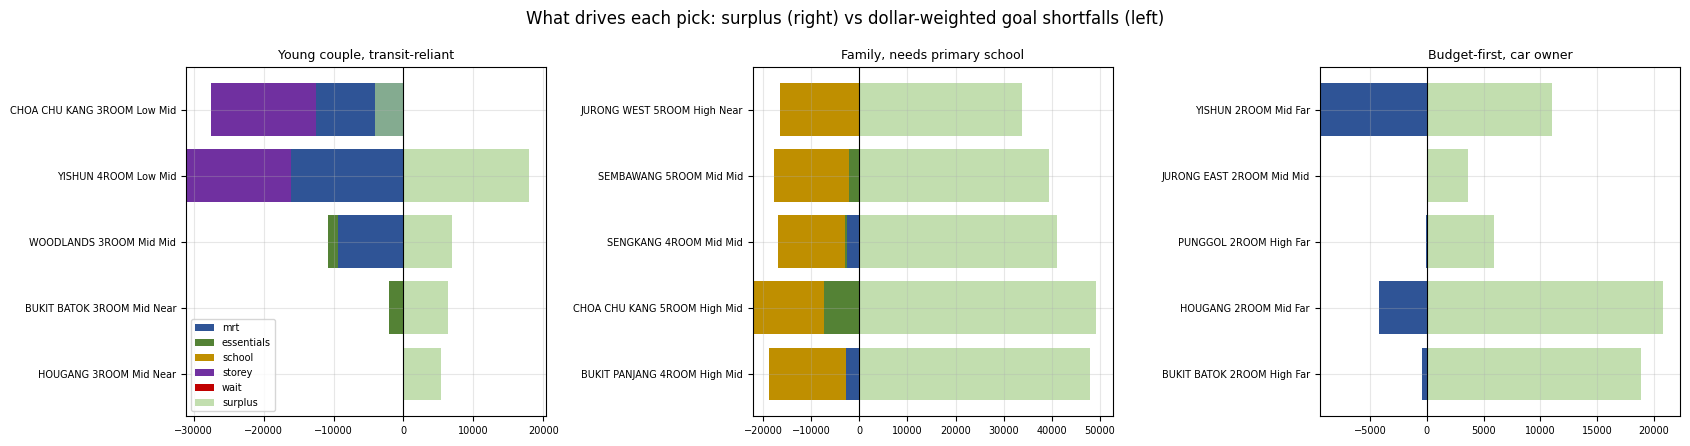

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=False)
devs = ["dev_mrt", "dev_essentials", "dev_school", "dev_storey", "dev_wait"]
for ax, (name, r) in zip(axes, results.items()):
    sl = r["shortlist"].set_index("profile_id")
    bottom = np.zeros(len(sl))
    for dcol, col in zip(devs, ["#2f5496", "#548235", "#bf8f00", "#7030a0", "#c00000"]):
        ax.barh(sl.index.str.replace("::", " "), -sl[dcol], left=-bottom, color=col, label=dcol.replace("dev_", ""))
        bottom += sl[dcol].values
    ax.barh(sl.index.str.replace("::", " "), sl["surplus"], color="#a9d18e", label="surplus", alpha=0.7)
    ax.axvline(0, color="black", lw=0.8); ax.set_title(name, fontsize=9); ax.tick_params(labelsize=7)
axes[0].legend(fontsize=7)
plt.suptitle("What drives each pick: surplus (right) vs dollar-weighted goal shortfalls (left)")
plt.tight_layout(); plt.show()

### Block drill-down for each shortlist (actual addresses behind each recommended profile)

In [22]:
for name, r in results.items():
    print(f"\n{name}")
    display(rv2.block_drilldown(r["shortlist"], top_n=2).round(3))


Young couple, transit-reliant


,profile_id,query,sales_12m,median_price,dist_mrt_exit_km
1787,BUKIT BATOK::3ROOM::Mid::Near,528 BT BATOK ST 51,7,410000.0,0.253
1781,BUKIT BATOK::3ROOM::Mid::Near,206 BT BATOK ST 21,2,456000.0,0.195
3508,CHOA CHU KANG::3ROOM::Low::Mid,10 TECK WHYE AVE,2,380000.0,0.489
3512,CHOA CHU KANG::3ROOM::Low::Mid,535 CHOA CHU KANG ST 51,2,454000.0,0.627
5075,HOUGANG::3ROOM::Mid::Near,528 HOUGANG AVE 6,4,502000.0,0.359
5074,HOUGANG::3ROOM::Mid::Near,511 HOUGANG AVE 10,1,488888.0,0.361
13085,WOODLANDS::3ROOM::Mid::Mid,694C WOODLANDS DR 62,3,522888.0,0.520
13087,WOODLANDS::3ROOM::Mid::Mid,784C WOODLANDS RISE,3,505000.0,0.734
14619,YISHUN::4ROOM::Low::Mid,305 YISHUN CTRL,3,560000.0,0.441
14649,YISHUN::4ROOM::Low::Mid,774 YISHUN AVE 3,3,492000.0,0.647



Family, needs primary school


,profile_id,query,sales_12m,median_price,dist_mrt_exit_km
2946,BUKIT PANJANG::4ROOM::High::Mid,629 SENJA RD,7,605000.0,0.644
2949,BUKIT PANJANG::4ROOM::High::Mid,633B SENJA RD,4,679000.0,0.506
3894,CHOA CHU KANG::5ROOM::High::Mid,14 TECK WHYE LANE,3,580000.0,0.503
3893,CHOA CHU KANG::5ROOM::High::Mid,13 TECK WHYE LANE,2,602444.0,0.462
6590,JURONG WEST::5ROOM::High::Near,517C JURONG WEST ST 52,1,841000.0,0.116
6591,JURONG WEST::5ROOM::High::Near,652B JURONG WEST ST 61,1,668000.0,0.121
9757,SEMBAWANG::5ROOM::Mid::Mid,126C CANBERRA ST,6,852500.0,0.627
9754,SEMBAWANG::5ROOM::Mid::Mid,120C CANBERRA CRES,3,818000.0,0.519
10463,SENGKANG::4ROOM::Mid::Mid,287A COMPASSVALE CRES,5,710888.0,0.675
10430,SENGKANG::4ROOM::Mid::Mid,203A COMPASSVALE RD,4,597500.0,0.441



Budget-first, car owner


,profile_id,query,sales_12m,median_price,dist_mrt_exit_km
1541,BUKIT BATOK::2ROOM::High::Far,467C BT BATOK WEST AVE 9,4,406500.0,1.072
1543,BUKIT BATOK::2ROOM::High::Far,468B BT BATOK WEST AVE 9,3,390000.0,0.983
4903,HOUGANG::2ROOM::Mid::Far,994A BUANGKOK LINK,4,389444.0,1.043
4898,HOUGANG::2ROOM::Mid::Far,987B BUANGKOK GREEN,4,375000.0,1.683
5693,JURONG EAST::2ROOM::Mid::Mid,371 JURONG EAST ST 32,2,353500.0,0.654
5694,JURONG EAST::2ROOM::Mid::Mid,372 JURONG EAST ST 32,2,335000.0,0.693
7969,PUNGGOL::2ROOM::High::Far,224C SUMANG LANE,4,425000.0,1.004
7977,PUNGGOL::2ROOM::High::Far,624C PUNGGOL CTRL,2,394194.0,1.167
14158,YISHUN::2ROOM::Mid::Far,459 YISHUN AVE 11,5,361000.0,1.498
14165,YISHUN::2ROOM::Mid::Far,672A YISHUN AVE 4,3,378000.0,0.912


### v1 vs v2 for the same household
Same budget, lease, flat types and k. v1 only knows town-level accessibility; we measure what MRT distance
its picks *actually* deliver using the block data.

In [23]:
recent = tx[tx["month"] > tx["month"].max() - pd.DateOffset(months=12)]
cmp_rows = []
for name, a in archetypes.items():
    q1 = rv1.HouseholdQuery(budget=a["budget"], min_lease_yrs=a["min_lease_yrs"], horizon_months=12, k=5,
                            flat_types=a.get("flat_types"), target_mrt_km=a["target_mrt_km"])
    r1 = rv1.solve_recommender(q1)["shortlist"]
    for _, p in r1.iterrows():
        cell = recent[(recent["town"] == p["town"]) & (recent["flat_type"] == p["flat_type"]) & (recent["storey_band"] == p["storey_band"])]
        cmp_rows.append({"household": name, "version": "v1 town-level", "profile": p["profile_id"],
                         "price": p["price_today"], "actual_mrt_km": cell["dist_mrt_exit_km"].median()})
    for _, p in results[name]["shortlist"].iterrows():
        cmp_rows.append({"household": name, "version": "v2 block-informed", "profile": p["profile_id"],
                         "price": p["price_today"], "actual_mrt_km": p["dist_mrt_exit_km_p50"]})
cmp = pd.DataFrame(cmp_rows)
summ = cmp.groupby(["household", "version"]).agg(median_mrt_km=("actual_mrt_km", "median"), mean_price=("price", "mean")).unstack()
summ.round(3)

median_mrt_km                      mean_price                  
version                       v1 town-level v2 block-informed v1 town-level v2 block-informed
household                                                                                    
Budget-first, car owner               1.216             1.020      375800.0          381400.0
Family, needs primary school          0.800             0.574      548088.8          637777.6
Young couple, transit-reliant         0.895             0.520      472000.0          471266.4

## 7. Monte Carlo: buy now vs wait (granularity-calibrated simulator)
Price paths now come from the **empirical 6/12-month bands for each pick's (flat type, MRT band)** — historical
median drift ≈ +4–7%/yr, not the old stub's 0%. Availability uses the arrival rate of matching sales.

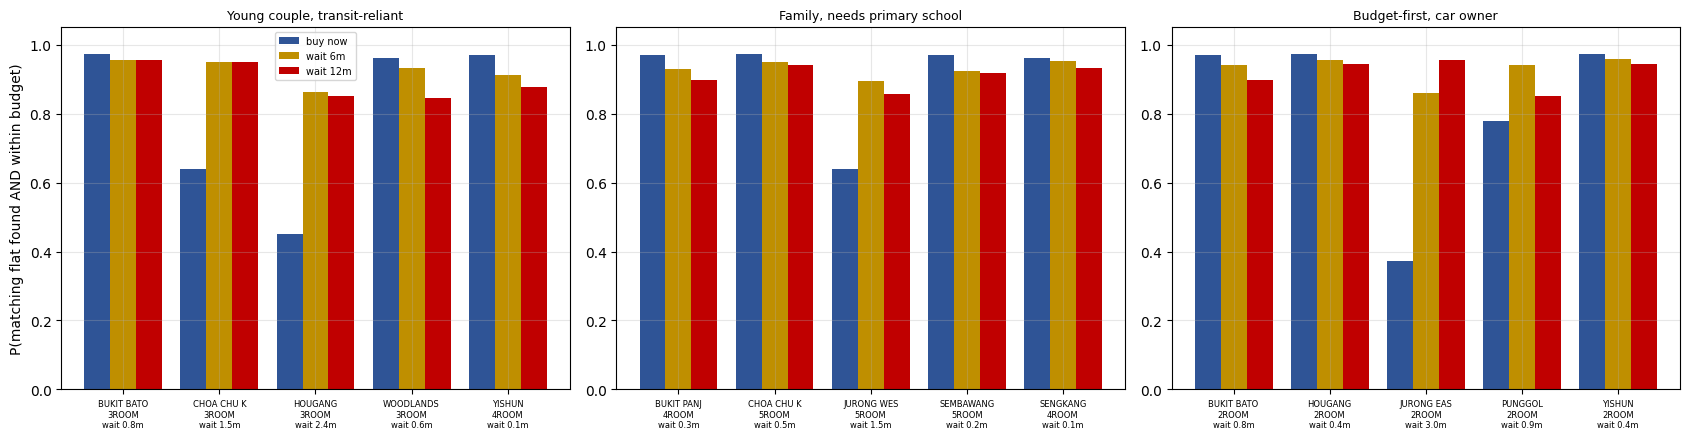

profile_id  expected_wait_months  buy_now_p_success_within_budget  wait_6m_p_success_within_budget  \
Young couple, transit-reliant 0    BUKIT BATOK::3ROOM::Mid::Near                  0.75                            0.971                            0.955   
                              1   CHOA CHU KANG::3ROOM::Low::Mid                  1.50                            0.640                            0.951   
                              2        HOUGANG::3ROOM::Mid::Near                  2.40                            0.452                            0.864   
                              3       WOODLANDS::3ROOM::Mid::Mid                  0.55                            0.962                            0.932   
                              4          YISHUN::4ROOM::Low::Mid                  0.12                            0.969                            0.911   
Family, needs primary school  0  BUKIT PANJANG::4ROOM::High::Mid                  0.26                            0.970                            0.929   
                              1  CHOA CHU KANG::5ROOM::High::Mid                  0.52                            0.971                            0.949   
                              2   JURONG WEST::5ROOM::High::Near                  1.50                            0.640                            0.895   
                              3       SEMBAWANG::5ROOM::Mid::Mid                  0.18                            0.969                            0.924   
                              4        SENGKANG::4ROOM::Mid::Mid                  0.09                            0.962                            0.953   
Budget-first, car owner       0    BUKIT BATOK::2ROOM::High::Far                  0.75                            0.970                            0.941   
                              1         HOUGANG::2ROOM::Mid::Far                  0.44                            0.971                            0.955   
                              2     JURONG EAST::2ROOM::Mid::Mid                  3.00                            0.372                            0.860   
                              3        PUNGGOL::2ROOM::High::Far                  0.92                            0.778                            0.942   
                              4          YISHUN::2ROOM::Mid::Far                  0.40                            0.974                            0.957   

                                 wait_12m_p_success_within_budget recommended_strategy  
Young couple, transit-reliant 0                             0.956              buy_now  
                              1                             0.948              wait_6m  
                              2                             0.852              wait_6m  
                              3                             0.846              buy_now  
                              4                             0.876              buy_now  
Family, needs primary school  0                             0.897              buy_now  
                              1                             0.941              buy_now  
                              2                             0.857              wait_6m  
                              3                             0.919              buy_now  
                              4                             0.931              buy_now  
Budget-first, car owner       0                             0.896              buy_now  
                              1                             0.944              buy_now  
                              2                             0.954             wait_12m  
                              3                             0.850              wait_6m  
                              4                             0.944              buy_now

In [24]:
mc_tables = {}
for name, r in results.items():
    sl = r["shortlist"]
    fc = eb.fcast_for_shortlist(sl, bands6, bands12)
    sc = mc.run_monte_carlo(sl, fc, n_scenarios=3000, seed=42)
    mc_tables[name] = mc.summarize_strategies(sc, budget=archetypes[name]["budget"]).merge(
        sl[["profile_id", "expected_wait_months"]], on="profile_id")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (name, s) in zip(axes, mc_tables.items()):
    xx = np.arange(len(s)); w = 0.27
    ax.bar(xx - w, s["buy_now_p_success_within_budget"], w, label="buy now", color="#2f5496")
    ax.bar(xx, s["wait_6m_p_success_within_budget"], w, label="wait 6m", color="#bf8f00")
    ax.bar(xx + w, s["wait_12m_p_success_within_budget"], w, label="wait 12m", color="#c00000")
    ax.set_xticks(xx); ax.set_xticklabels([f"{p.split('::')[0][:10]}\n{p.split('::')[1]}\nwait {wt:.1f}m"
                                           for p, wt in zip(s["profile_id"], s["expected_wait_months"])], fontsize=6)
    ax.set_ylim(0, 1.05); ax.set_title(name, fontsize=9)
axes[0].set_ylabel("P(matching flat found AND within budget)"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()
pd.concat({k: v[["profile_id", "expected_wait_months", "buy_now_p_success_within_budget", "wait_6m_p_success_within_budget",
                 "wait_12m_p_success_within_budget", "recommended_strategy"]] for k, v in mc_tables.items()}).round(3)

**Reading it.** Liquid profiles (a matching sale every few weeks) → **buy now**: waiting only adds price risk.
Thinner profiles → buying within a ~6-week search often fails, so **waiting ~6 months** raises the chance of a
match before price drift erodes the budget; 12 months tends to be worse than 6. This is the
"how readily does it come up for sale" business objective made decision-relevant.

### 7.1 "About 5% of picks saw no matching sale" — was that predictable?
**What it means.** The backtest checks each pick by looking for actual resales *of that exact profile*
(same town, flat type, storey band and MRT band) in months 11–13 after the cutoff. For ~4–5% of v2 picks there
were **none** — not a bad recommendation, simply no flat of that kind changed hands in that 3-month window, so
a buyer would have had to wait. The coarser v1 (town-level) profiles almost never hit this because each covers
more flats.

**The test.** The availability stub models matching sales as a Poisson arrival process: a profile with n sales
in the past 12 months produces n/12 per month, so P(no sale in 3 months) = exp(−3n/12). If the model is
honest, picks it flagged as risky should be the ones that came up empty.

In [25]:
from backtest_v2 import availability_calibration
bt_raw = pd.read_csv(os.path.join(DATA, "backtest_v2_results_iter2.csv"))
cal_d, cal = availability_calibration(bt_raw, tx)
print(f"Expected no-sale picks: {cal_d['p_no_sale_pred'].sum():.1f}  |  observed: {cal_d['no_sale_observed'].sum()} of {len(cal_d)}")
display(cal.round(3))
cal_d[cal_d["no_sale_observed"] == 1][["cutoff", "household", "profile", "sales_prev_12m", "p_no_sale_pred"]].round(3)

Expected no-sale picks: 3.3  |  observed: 4 of 90


,picks,mean_predicted,observed_rate,observed_count
risk_bucket,,,,
<1%,66,0.001,0.000,0
1-10%,13,0.033,0.077,1
10-30%,8,0.180,0.000,0
>30%,3,0.472,1.000,3


,cutoff,household,profile,sales_prev_12m,p_no_sale_pred
312,2024-01-01,"Budget-first, car owner",BUKIT BATOK::2ROOM::High::Mid,13,0.039
334,2025-01-01,"Young couple, transit-reliant",CHOA CHU KANG::3ROOM::High::Mid,3,0.472
356,2025-07-01,"Budget-first, car owner",TOA PAYOH::3ROOM::High::Mid,3,0.472
358,2025-07-01,"Budget-first, car owner",JURONG EAST::2ROOM::High::Far,3,0.472


**Reading it.** Expected and observed counts are close in aggregate (printed above), and the misses
are concentrated where the model said they would be: every pick with >30% predicted no-sale risk came up empty;
the 66 picks rated <1% never did. So this is a *known, priced risk*, not a hidden failure — the shortlist
now shows `p_no_matching_sale_3m` beside each pick, and the Monte Carlo turns it into "buy now vs wait".
The Pricing & Availability Lead's survival model should beat this stub on the same table.

## 8. Sensitivity

Budget monotonicity (comparable full-k solutions): PASS
Min-lease monotonicity: PASS


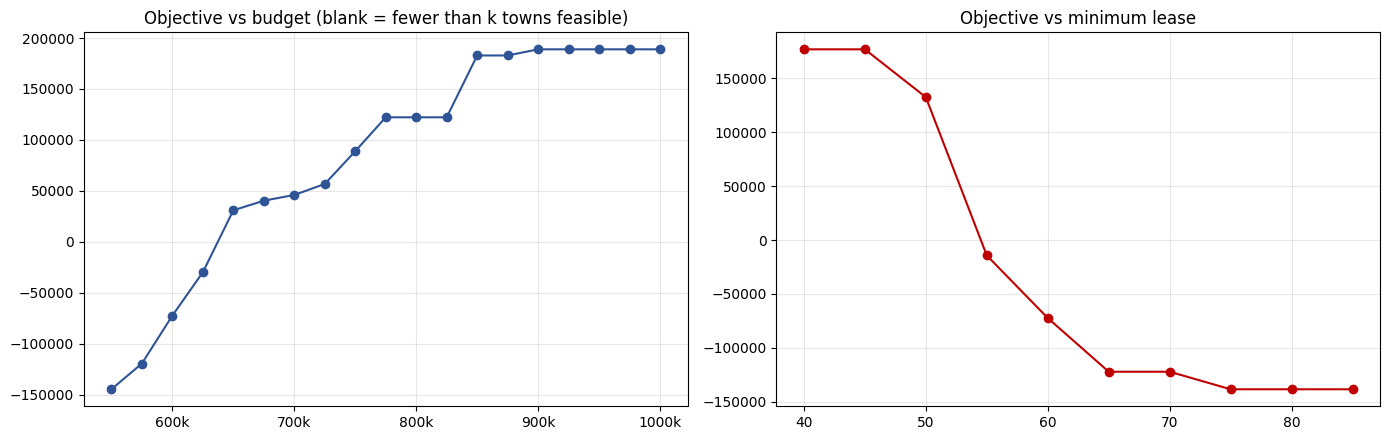

In [26]:
base = dict(budget=600_000, min_lease_yrs=60, k=5, flat_types=["3 ROOM", "4 ROOM"], target_mrt_km=0.5)
bs = sv2.sweep(base, "budget", range(450_000, 1_000_001, 25_000), upper_factors=bands12)
ls = sv2.sweep(base, "min_lease_yrs", range(40, 96, 5), upper_factors=bands12)
ok_b, _ = sv2.monotonic(bs, "objective", "budget", True); ok_l, _ = sv2.monotonic(ls, "objective", "min_lease_yrs", False)
print("Budget monotonicity (comparable full-k solutions):", "PASS" if ok_b else "FAIL")
print("Min-lease monotonicity:", "PASS" if ok_l else "FAIL")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(bs["budget"], bs["objective"], "o-", color="#2f5496"); axes[0].xaxis.set_major_formatter(kfmt)
axes[0].set_title("Objective vs budget (blank = fewer than k towns feasible)")
axes[1].plot(ls["min_lease_yrs"], ls["objective"], "o-", color="#c00000"); axes[1].set_title("Objective vs minimum lease")
plt.tight_layout(); plt.show()

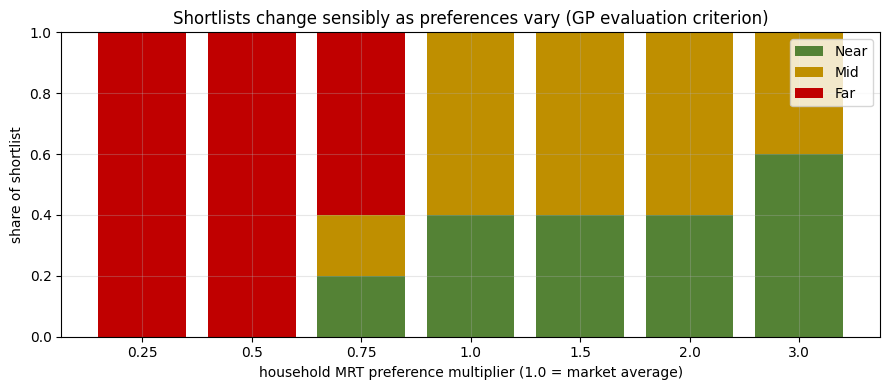

,mrt_multiplier,share_Near,share_Mid,share_Far,n_candidates,n_feasible_towns,k_satisfied,median_pick_mrt_km,mean_pick_price
0,0.25,0.0,0.0,1.0,27,8,True,1.043,497600.0
1,0.50,0.0,0.0,1.0,27,8,True,1.043,497600.0
2,0.75,0.2,0.2,0.6,27,8,True,0.827,481000.0
3,1.00,0.4,0.6,0.0,27,8,True,0.520,467266.4
4,1.50,0.4,0.6,0.0,27,8,True,0.520,471266.4
5,2.00,0.4,0.6,0.0,27,8,True,0.520,471266.4
6,3.00,0.6,0.4,0.0,27,8,True,0.359,463444.0


In [27]:
ps = sv2.mrt_preference_sweep(base, multipliers=(0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0), upper_factors=bands12)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(ps["mrt_multiplier"].astype(str), ps["share_Near"], color="#548235", label="Near")
ax.bar(ps["mrt_multiplier"].astype(str), ps["share_Mid"], bottom=ps["share_Near"], color="#bf8f00", label="Mid")
ax.bar(ps["mrt_multiplier"].astype(str), ps["share_Far"], bottom=ps["share_Near"] + ps["share_Mid"], color="#c00000", label="Far")
ax.set_xlabel("household MRT preference multiplier (1.0 = market average)"); ax.set_ylabel("share of shortlist")
ax.set_title("Shortlists change sensibly as preferences vary (GP evaluation criterion)"); ax.legend()
plt.tight_layout(); plt.show()
ps.drop(columns=["picks", "objective"]).round(3)

### Price of insisting
The proposal asks what insisting on a requirement *costs*. With MRT bands this is now answerable directly:
**the minimum budget at which the household can still get a full shortlist of k options**, with and without
the requirement.

In [28]:
def min_budget_for_k(extra):
    sw = sv2.sweep({**base, **extra}, "budget", range(400_000, 1_200_001, 10_000), upper_factors=bands12)
    ok = sw[sw["k_satisfied"]]
    return ok["budget"].min() if len(ok) else np.nan
rows = []
for label, extra in [("baseline (MRT, lease as soft goals)", {}), ("insist on Mid or better (≤800m)", {"max_mrt_band": "Mid"}),
                     ("insist on Near (≤400m)", {"max_mrt_band": "Near"}), ("insist on lease ≥ 80 yrs", {"min_lease_yrs": 80}),
                     ("insist on Near AND lease ≥ 80", {"max_mrt_band": "Near", "min_lease_yrs": 80})]:
    rows.append({"requirement": label, "min_budget_for_5_options": min_budget_for_k(extra)})
poi = pd.DataFrame(rows)
poi["price_of_insisting_sgd"] = poi["min_budget_for_5_options"] - poi["min_budget_for_5_options"].iloc[0]
poi

,requirement,min_budget_for_5_options,price_of_insisting_sgd
0,"baseline (MRT, lease as soft goals)",540000,0
1,insist on Mid or better (≤800m),600000,60000
2,insist on Near (≤400m),670000,130000
3,insist on lease ≥ 80 yrs,590000,50000
4,insist on Near AND lease ≥ 80,880000,340000


## 9. Backtest — 6 cutoffs × 3 households
At each cutoff (2023-01 … 2025-07) profiles **and the hedonic** are rebuilt from data available then; picks are
scored on what actually happened 12 months later. Results come from `backtest_v2.py` (≈25 min to regenerate:
`python backtest_v2.py`, then `run_v2_variant(...)` for iteration 2).

In [29]:
bt = pd.read_csv(os.path.join(DATA, "backtest_v2_results_iter2.csv"))
label = {"naive_cheapest_towns": "naive", "v1_town_level": "v1 town", "v2_block_informed": "v2 iter1 (stub band)",
         "v2_block_informed_empirical_band": "v2 iter2 (empirical band)"}
bt["strategy"] = bt["strategy"].map(label)
from backtest_v2 import summarise
s = summarise(bt); s

,picks,share_within_budget_12m,share_with_matching_sale_seen,median_realised_price_CV_pct,median_pick_mrt_km,median_realised_vs_cutoff_pct
strategy,,,,,,
naive,90,1.000000,0.933333,8.852868,0.739406,8.019571
v1 town,90,1.000000,1.000000,10.053530,0.799407,8.428700
v2 iter1 (stub band),90,0.941860,0.955556,9.301856,0.577852,7.913043
v2 iter2 (empirical band),90,0.988372,0.955556,7.878432,0.586974,7.735285


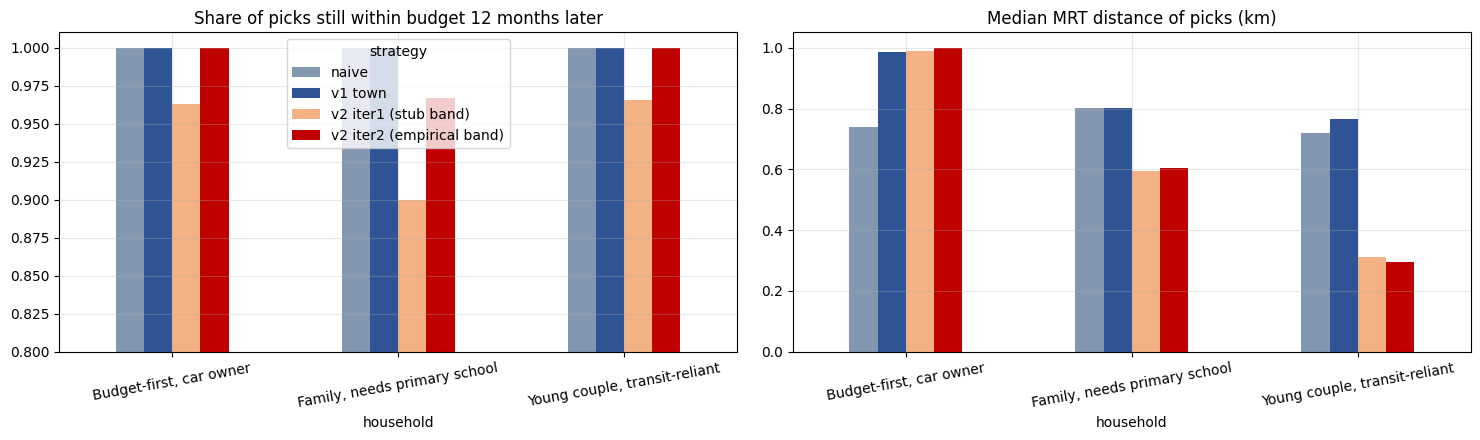

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
wb = bt.groupby(["household", "strategy"])["within_budget"].mean().unstack()
wb.plot(kind="bar", ax=axes[0], color=["#8497b0", "#2f5496", "#f4b183", "#c00000"])
axes[0].set_ylim(0.8, 1.01); axes[0].set_title("Share of picks still within budget 12 months later"); axes[0].tick_params(axis="x", rotation=10)
mk = bt.groupby(["household", "strategy"])["pick_mrt_km"].median().unstack()
mk.plot(kind="bar", ax=axes[1], color=["#8497b0", "#2f5496", "#f4b183", "#c00000"], legend=False)
axes[1].set_title("Median MRT distance of picks (km)"); axes[1].tick_params(axis="x", rotation=10)
plt.tight_layout(); plt.show()

In [31]:
bt["realised_chg_pct"] = (bt["realised_price"] / bt["price_at_cutoff"] - 1) * 100
bt["price_to_budget"] = bt["price_at_cutoff"] / bt["budget"]
print("Remaining / earlier failures:")
bt[bt["within_budget"] == 0][["cutoff", "household", "strategy", "profile", "price_to_budget", "realised_chg_pct",
                              "matched_sales_in_window"]].round(3)

Remaining / earlier failures:


,cutoff,household,strategy,profile,price_to_budget,realised_chg_pct,matched_sales_in_window
60,2023-07-01,"Family, needs primary school",v2 iter1 (stub band),BUKIT PANJANG::5ROOM::High::Mid,0.847,20.472,7
90,2024-01-01,"Young couple, transit-reliant",v2 iter1 (stub band),BISHAN::3ROOM::Mid::Near,0.845,20.000,7
105,2024-01-01,"Family, needs primary school",v2 iter1 (stub band),BUKIT PANJANG::5ROOM::High::Mid,0.867,29.846,2
195,2025-01-01,"Family, needs primary school",v2 iter1 (stub band),JURONG WEST::5ROOM::High::Near,0.807,24.711,2
259,2025-07-01,"Budget-first, car owner",v2 iter1 (stub band),TAMPINES::2ROOM::Mid::Mid,0.859,16.921,1
335,2025-01-01,"Family, needs primary school",v2 iter2 (empirical band),JURONG WEST::5ROOM::High::Near,0.807,24.711,2


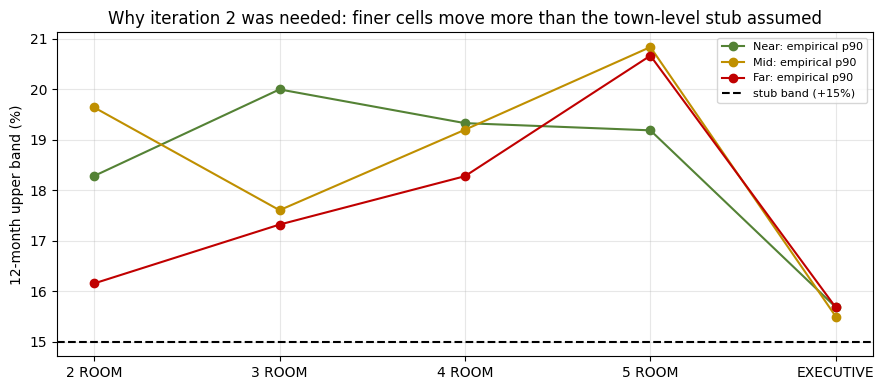

In [32]:
b_all = eb.empirical_growth_bands(tx[tx["flat_type"] != "MULTI-GENERATION"], horizon=12)
b_all = b_all[b_all["n_obs"] >= 100]
fig, ax = plt.subplots(figsize=(9, 4))
for band, col in [("Near", "#548235"), ("Mid", "#bf8f00"), ("Far", "#c00000")]:
    s = b_all[b_all["mrt_band"].astype(str) == band]
    ax.plot(s["flat_type"], (s["growth_factor_upper"] - 1) * 100, "o-", color=col, label=f"{band}: empirical p90")
ax.axhline(15, color="black", ls="--", label="stub band (+15%)")
ax.set_ylabel("12-month upper band (%)"); ax.legend(fontsize=8)
ax.set_title("Why iteration 2 was needed: finer cells move more than the town-level stub assumed")
plt.tight_layout(); plt.show()

## 10. Conclusions, limitations, handoff notes

**What block-level geocoding bought us**
- 63–96% of accessibility variation is within towns; town centroids discarded most of it.
- Block accessibility explains price beyond town (adj R² 0.918 → 0.935; out-of-time MAPE 16.1% → 15.6%);
  MRT proximity is worth ≈1.1% per 100m within a town, with a clean monotone gradient.
- At the recommender level: for a transit-reliant household, picks are **~60% closer to MRT** than v1's,
  at the same budget, with **lower price dispersion** for the buyer — and v2 correctly does *not* buy MRT
  access for a car owner.
- The cost: finer profiles are noisier. With a granularity-aware price band (iteration 2), within-budget
  robustness recovers to 98.8% (v1: 100%); ~5% of finer profiles see no matching sale within the window —
  predicted by the availability model (§7.1) and surfaced as `p_no_matching_sale_3m` / expected wait.
- School access as MOE tiers: SAP/GEP within 2km ≈ +2.5–3%, now the market rate for the school goal.

**Limitations**
- Hedonic and profile distances are straight-line. OSM walking distances were computed for every block, but
  OSM under-maps HDB-estate crossings/linkways, and walking distance did not explain price better (§3.4).
  They are kept as `walk_*` columns for display and robustness, not as the model input.
- Rail access is date-aware at month resolution (a station opening mid-month counts from the next month);
  interchange stations are treated as open throughout because their older line was already running.
- SAP/GEP is a proxy for "popular school"; P1 balloting data would be better.
- The hedonic is an interim stand-in for the Pricing & Availability Lead's model; linear school/childcare
  distance coefficients are not used.
- Availability is still a stub (Poisson arrival of matching sales), pending KM/Cox PH.

**Handoff notes**
- *Pricing & Availability:* `transactions_block_access.parquet` already joins every sale to block accessibility;
  `housing_profiles_v2_full.csv` carries dwelling-unit exposure per profile for the survival model.
- *Forecasting:* please report interval coverage at **G2 granularity**; `empirical_bands.py` is the benchmark
  your SARIMAX intervals should beat (target: ≥90% coverage, narrower than the empirical band).
- *Preference:* conjoint WTP plugs in as household multipliers relative to `market_wtp_coefficients.json`
  (revealed WTP) — the gap between stated and revealed WTP is itself a reportable finding.
